# ベルマン方程式：リンゴと壁のゲームで考える

『ゼロから作る Deep Learning ❹』第 3 章 3.1〜3.3 の輪読会資料

「今リンゴを取れたら、その選び方はよいのだろうか。それとも、その後に壁へぶつかることまで考える必要があるだろうか。」

今回は前回と同じ 2 マスのゲームを使い、**実際のプレイ → 起こりうるプレイの平均 → 数式**の順で考える。ベルマン方程式が表すのは、今もらう点数と、その先に見込める点数を合わせて場所や行動を評価することである。

まずは図と点数の表を読み、何を平均しているかを確かめよう。詳しい式変形や行列の説明は、開いて読める補足にまとめた。


## 目次と今回の目標

| 節 | 内容 | 目標 |
|---|---|---|
| 3.1.1 | 確率と期待値（ベルマン方程式のための下準備） | 条件付き確率から期待値を計算する |
| 3.1.2 | ベルマン方程式の導出 | 収益の再帰関係から価値の関係式を導く |
| 3.2.1 | 2マスのグリッドワールド | 2 本の方程式を立て、状態価値を求める |
| 3.2.2 | ベルマン方程式の意義 | 無限の将来を次状態の価値にまとめる意味を説明する |
| 3.3.1 | 行動価値関数 | 状態価値と行動価値、報酬を区別する |
| 3.3.2 | 行動価値関数を使ったベルマン方程式 | $v_\pi$ と $q_\pi$ の関係を確かめる |

節・小節の対応は[出版社の目次](https://www.oreilly.co.jp/books/9784873119755/)を参照する。解説と追加実験は輪読用に構成した。

前回の資料は [2.3〜2.5 の Notebook](ch02_sec2.3-2.5.ipynb)。この Notebook は単独で実行できるように、必要な環境の定義をもう一度用意する。ここでは**与えられた方策を評価する**。ベルマン最適方程式は次の 3.4 で扱う。


## 実行の準備と読み進め方

NumPy、Pandas、Matplotlib を使う。リポジトリのルートで次を実行し、セルを上から順に実行する。

```bash
uv run --extra notebooks jupyter lab my_notebooks
```

最初は各節の**具体例・表・図**を中心に読む。式の変形を確認したくなったら「補足」を開く。作図用のコードも折り畳んである。コードを開かずに出力だけ読んでも、例を追えるようにしている。

図内は英語、説明文と表は日本語を使う。外部データや他の Notebook の実行結果は使わない。実験では、乱数で試す代わりに、起こりうる場合をすべて数えて平均を求める。


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, Rectangle
from IPython.display import display

GAMMA = 0.9
COLORS = ["#1B6CA8", "#0A8F7A", "#D27D2D", "#955277"]
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18, "font.size": 18,
    "axes.titlesize": 22, "axes.titlepad": 16, "axes.labelsize": 20,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 16,
    "axes.prop_cycle": matplotlib.cycler(color=COLORS),
})
print("Python", sys.version.split()[0])
print("NumPy", np.__version__, "/ Pandas", pd.__version__,
      "/ Matplotlib", matplotlib.__version__)


Python 3.11.15
NumPy 1.23.5 / Pandas 2.3.3 / Matplotlib 3.10.9


In [2]:
# 図で共通に使う、計算のカード・矢印・小さな盤面。
from matplotlib.patches import FancyBboxPatch

def diagram_card(ax, x, y, width, height, title, body,
                 face="#EAF4F7", edge="#1B6CA8", title_size=19, body_size=18):
    ax.add_patch(FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.025,rounding_size=0.10",
        facecolor=face, edgecolor=edge, linewidth=2))
    ax.text(x + width / 2, y + height * 0.76, title,
            ha="center", va="center", fontsize=title_size, color=edge)
    ax.text(x + width / 2, y + height * 0.34, body,
            ha="center", va="center", fontsize=body_size,
            color="#202B33", linespacing=1.35)

def diagram_arrow(ax, start, end, label=None, text_xy=None, color="#64748B"):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                                mutation_scale=22, linewidth=2.3, color=color))
    if label is not None:
        if text_xy is None:
            text_xy = ((start[0] + end[0]) / 2, (start[1] + end[1]) / 2)
        ax.text(*text_xy, label, ha="center", va="center", fontsize=17,
                bbox=dict(facecolor="white", edgecolor="none", pad=3))

def diagram_state(ax, xy, name):
    ax.add_patch(Circle(xy, 0.33, facecolor="#EAF4F7", edgecolor=COLORS[0], lw=2))
    ax.text(*xy, name, ha="center", va="center", fontsize=22)

def diagram_board(ax, x, y, state, apple):
    for cell in range(2):
        ax.add_patch(Rectangle((x + cell, y), 1, 1.1,
                               facecolor="#F1F5F9", edgecolor="#64748B", lw=1.6))
        ax.text(x + cell + 0.5, y + 0.87, f"L{cell + 1}",
                ha="center", va="center", fontsize=18)
    ax.add_patch(Circle((x + state + 0.5, y + 0.34), 0.17,
                        facecolor=COLORS[0], edgecolor=COLORS[0]))
    if apple:
        ax.add_patch(Circle((x + 1.5, y + 0.34), 0.17,
                            facecolor="#D94A46", edgecolor="#AD3431"))
        ax.plot([x + 1.5, x + 1.59], [y + 0.51, y + 0.63],
                color=COLORS[1], linewidth=3)


## まずは、リンゴと壁のゲームを 1 回遊ぶ

左のマスを **L1**、右のマスを **L2** と呼ぶ。L1 から始め、1 手ごとにコインを投げて、表なら左、裏なら右を選ぶ。左右はそれぞれ半分の確率で選ばれる。

| 今いる場所 | 左を選ぶと | 右を選ぶと |
|---|---|---|
| L1 | 左の壁にぶつかる。L1 に残って **−1 点** | L2 に移り、リンゴを取って **＋1 点** |
| L2 | L1 に戻って **0 点**。リンゴが再び現れる | 右の壁にぶつかる。L2 に残って **−1 点** |

リンゴを取ってもゲームは続く。今回は、このコイン任せの遊び方で、どのくらい点数を得られるかを調べる。


In [3]:
# 以降の例で共通に使うゲームのルール。
# 状態は 0=L1, 1=L2、行動は 0=左, 1=右。
STATE_NAMES = np.array(["L1", "L2"])
ACTION_NAMES = np.array(["Left", "Right"])
NEXT_STATE = np.array([[0, 1], [0, 1]], dtype=np.int64)
REWARD = np.array([[-1.0, 1.0], [0.0, -1.0]])
POLICY = np.full((2, 2), 0.5)
np.testing.assert_allclose(POLICY.sum(axis=1), 1.0)


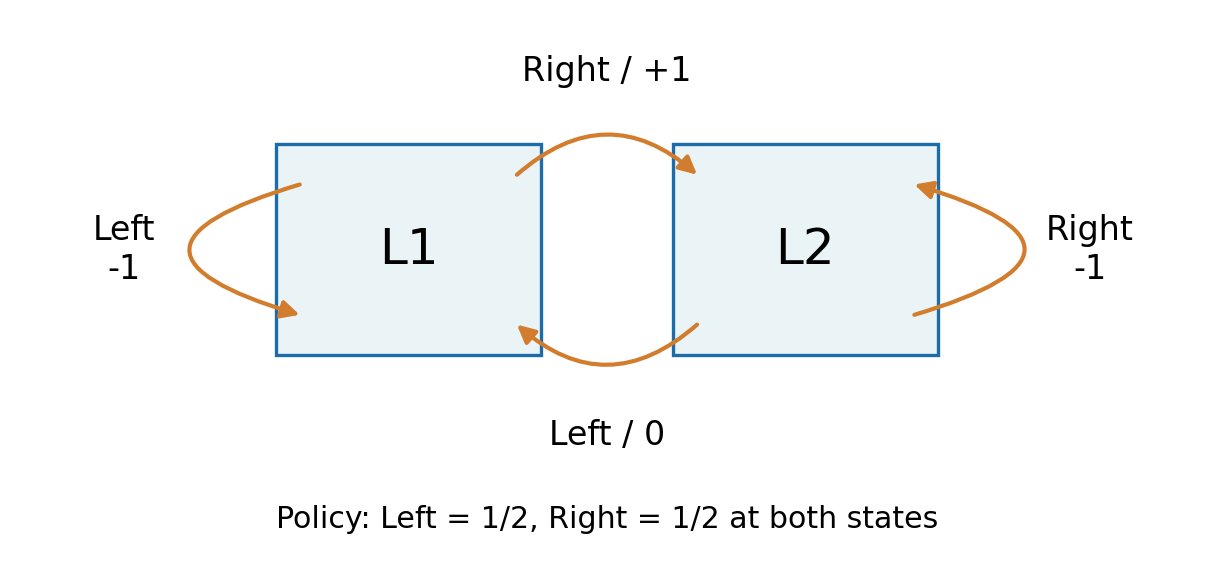

In [4]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.axis("off")
for x, name in [(0, "L1"), (3, "L2")]:
    ax.add_patch(Rectangle((x, 0), 2, 1.6, facecolor="#EAF4F7",
                           edgecolor=COLORS[0], linewidth=2))
    ax.text(x + 1, 0.8, name, ha="center", va="center", fontsize=30)

# 左右に移動する矢印と、壁に当たって同じ状態へ戻る矢印。
arrows = [
    ((1.8, 1.35), (3.2, 1.35), "arc3,rad=-0.45", (2.5, 2.15), "Right / +1"),
    ((3.2, 0.25), (1.8, 0.25), "arc3,rad=-0.45", (2.5, -0.6), "Left / 0"),
    ((0.2, 1.3), (0.2, 0.3), "arc3,rad=1.7", (-1.15, 0.8), "Left\n-1"),
    ((4.8, 0.3), (4.8, 1.3), "arc3,rad=1.7", (6.15, 0.8), "Right\n-1"),
]
for start, end, connection, text_xy, label in arrows:
    ax.add_patch(FancyArrowPatch(start, end, connectionstyle=connection,
                                arrowstyle="-|>", mutation_scale=22,
                                linewidth=2.5, color=COLORS[2]))
    ax.text(*text_xy, label, ha="center", va="center", fontsize=20)
ax.text(2.5, -1.3, "Policy: Left = 1/2, Right = 1/2 at both states",
        ha="center", fontsize=18)
ax.set(xlim=(-2, 7), ylim=(-1.6, 2.6), aspect="equal")
plt.show()


図 1：矢印の数値は、その移動で得る点数である。外側の矢印は、壁にぶつかって同じ場所に残ることを表す。

たとえばコインの結果が「右 → 左 → 右」だったら、次のように進む。

| 何手目 | 今いる場所 | 選んだ行動 | 次の場所 | もらう点数 |
|---|---|---|---|---:|
| 1 手目 | L1 | 右 | L2 | ＋1 |
| 2 手目 | L2 | 左 | L1 | 0 |
| 3 手目 | L1 | 右 | L2 | ＋1 |

実際にもらう合計は 2 点である。ただし将来の点数は少し軽く見積もることにして、1 手先は 0.9 倍、2 手先は 0.81 倍として足す。この **0.9 が割引率**である。

この 3 手だけの割引後の合計は **1 ＋ 0.9 × 0 ＋ 0.81 × 1 ＝ 1.81 点**になる。割引しているのは評価のための重みであり、受け取ったリンゴの点数そのものが変わるわけではない。

これは、たまたまこの順に行動した **1 回のプレイ**の結果である。「L1 から遊ぶと平均して何点か」を知るには、ほかに起こりうるプレイも含めて考える必要がある。


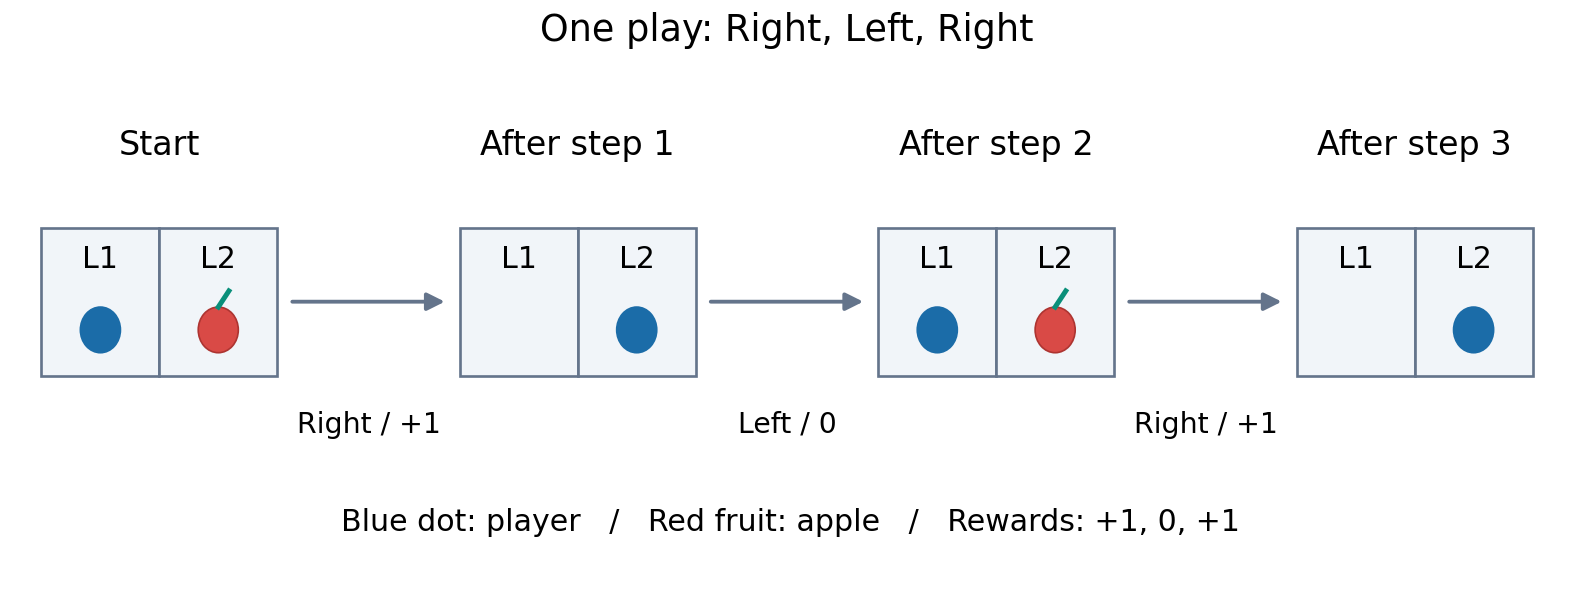

In [5]:
fig, ax = plt.subplots(figsize=(13, 4.8), layout="constrained")
ax.axis("off")
board_x = [0.1, 3.65, 7.2, 10.75]
for i, (x, state, apple) in enumerate(zip(board_x, [0, 1, 0, 1],
                                         [True, False, True, False])):
    diagram_board(ax, x, 0.45, state, apple)
    ax.text(x + 1, 2.1, "Start" if i == 0 else f"After step {i}",
            ha="center", fontsize=20)
for i, label in enumerate(["Right / +1", "Left / 0", "Right / +1"]):
    start, end = (board_x[i] + 2.1, 1), (board_x[i + 1] - 0.1, 1)
    diagram_arrow(ax, start, end)
    ax.text((start[0] + end[0]) / 2, 0.03, label, ha="center", fontsize=17)
ax.text(6.45, -0.7, "Blue dot: player   /   Red fruit: apple   /   Rewards: +1, 0, +1",
        ha="center", fontsize=18)
ax.set(xlim=(-0.15, 13), ylim=(-1.05, 2.75),
       title="One play: Right, Left, Right")
plt.show()


図 2：青い丸が自分、赤い実がリンゴである。左から右へ、1 回のプレイを順に追う。右へ進んでリンゴを取ると消え、左へ戻ると再び現れる。最後の右でまたリンゴを取るので、受け取る点数は「＋1、0、＋1」となる。これはコインの結果がこの順になった 1 回の例である。


<details>
<summary>補足：記号の早見表（必要になったら参照）</summary>

### 記号の復習

| 記号 | 意味 |
|---|---|
| $S_t, A_t, R_t$ | 時刻 $t$ の状態、行動、その行動の結果として受け取る報酬 |
| $s, a, s'$ | 現在の状態、行動、次の状態の具体的な値 |
| $p(s'\mid s,a)$ | 状態 $s$ で行動 $a$ を選んだとき、$s'$ へ移る確率 |
| $r(s,a,s')$ | その遷移で受け取る報酬。報酬自体も確率的なら、その条件付き期待値 |
| $\pi(a\mid s)$ | 状態 $s$ で行動 $a$ を選ぶ確率 |
| $\gamma$ | 割引率。今回の連続タスクでは $0\leq\gamma<1$ |
| $G_t$ | 時刻 $t$ から先の収益。$G_t=\sum_{k=0}^{\infty}\gamma^kR_{t+k}$ |
| $v_\pi(s)$ | 状態 $s$ から方策 $\pi$ に従うときの収益の期待値 |

前回と同じく、報酬の添字は $S_t\rightarrow A_t\rightarrow(R_t,S_{t+1})$ の順にする。$s'$ のプライムは「次の状態」の印であり、微分ではない。

以下では有限個の状態・行動と、有界な報酬を考える。方策と環境の規則は時刻によって変わらないものとする。添字 $\pi$ は「どの方策を評価しているか」を表す。

</details>


# 3.1 ベルマン方程式の導出
## 3.1.1 確率と期待値（ベルマン方程式のための下準備）

### 具体例：くじを 100 回引くと、平均で何点になる？

まず将来の話をいったん外し、1 回の報酬の平均を考える。A と B の 2 種類のくじがあり、当たりなら 1 点、外れなら 0 点を得る。毎回、A を 40%、B を 60% の確率で選ぶとする。

| くじ | 100 回引くときの選択回数の目安 | 当たる確率 | 当たり回数の目安 |
|---|---:|---:|---:|
| A | 40 回 | 20% | 40 × 0.2 ＝ 8 回 |
| B | 60 回 | 70% | 60 × 0.7 ＝ 42 回 |
| 合計 | 100 回 | — | **50 回** |

合計で 50 点が見込まれるので、1 回あたりでは **50 ÷ 100 ＝ 0.5 点**。このように、結果をその起こりやすさで重み付けした平均が**期待値**である。100 回で必ず 50 点になるという意味ではなく、実際の回数や点数にはばらつきがある。

「A を選んだと分かっているなら、平均何点か」の答えは 0.2 点、「B なら」の答えは 0.7 点である。条件を絞って考えた平均を**条件付き期待値**という。


In [6]:
toy_policy = np.array([0.4, 0.6])
toy_rewards = np.array([0.0, 1.0])
toy_reward_probs = np.array([[0.8, 0.2], [0.3, 0.7]])

conditional_means = (toy_reward_probs * toy_rewards).sum(axis=1)
joint_probs = toy_policy[:, None] * toy_reward_probs
expected_counts = 100 * joint_probs

display(pd.DataFrame(expected_counts, index=["くじ A", "くじ B"],
                     columns=["100 回中の外れ回数の目安", "100 回中の当たり回数の目安"]))
expected_by_actions = np.sum(toy_policy * conditional_means)
expected_by_outcomes = np.sum(joint_probs * toy_rewards)
print(f"当たり回数の目安：{expected_counts[:, 1].sum():.0f} 回")
print(f"1 回あたりの期待報酬：{expected_by_actions:.1f} 点")
np.testing.assert_allclose(toy_reward_probs.sum(axis=1), 1.0)
np.testing.assert_allclose(joint_probs.sum(), 1.0)
np.testing.assert_allclose([expected_by_actions, expected_by_outcomes], 0.5)


,100 回中の外れ回数の目安,100 回中の当たり回数の目安
くじ A,32.0,8.0
くじ B,18.0,42.0


当たり回数の目安：50 回
1 回あたりの期待報酬：0.5 点


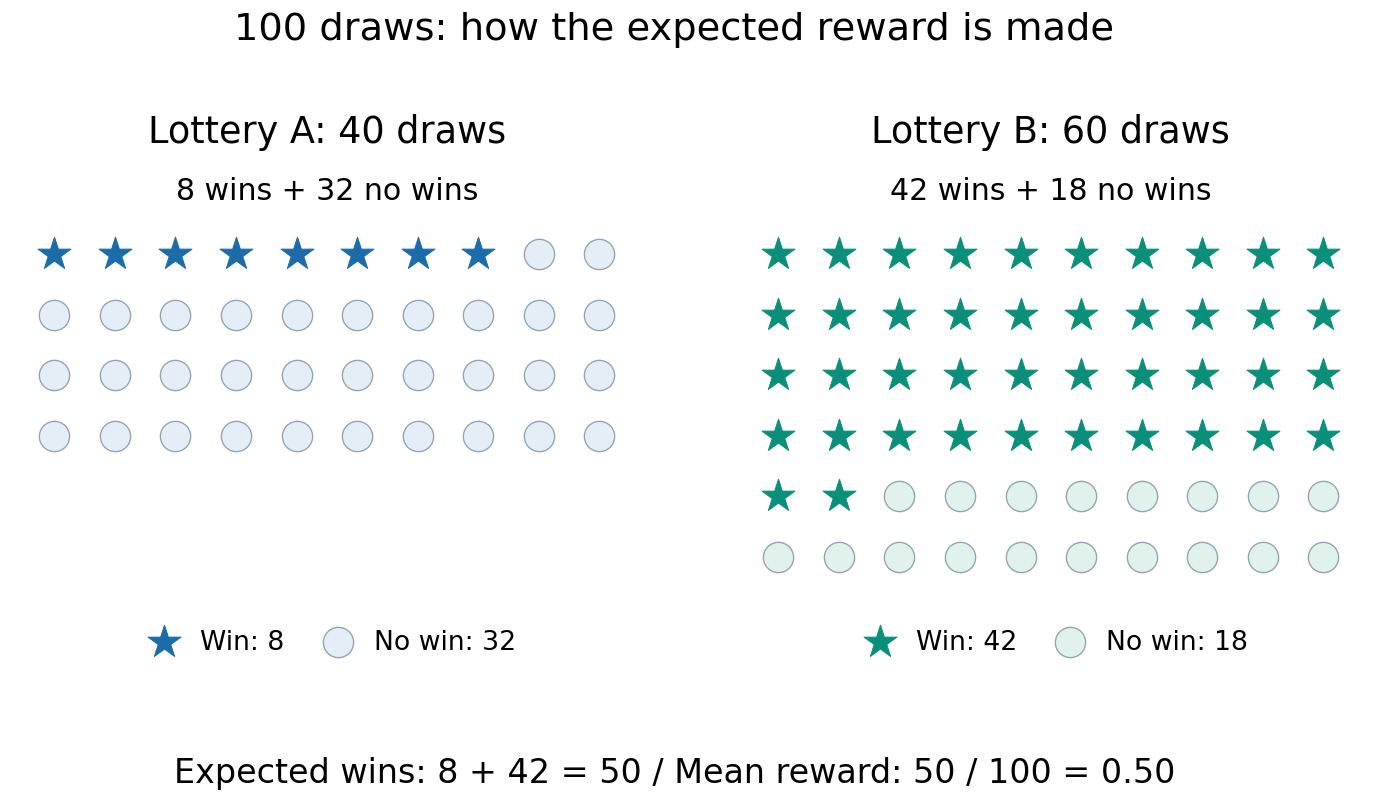

In [7]:
# 確率から得た期待回数を、1 個が 1 回に対応する点で表す。
# この例では期待回数が整数になるので、100 個の点にそのまま対応させられる。
fig, axes = plt.subplots(1, 2, figsize=(12, 6.8))
fig.subplots_adjust(left=0.04, right=0.98, top=0.84, bottom=0.20, wspace=0.15)
for group, (ax, name, color, pale) in enumerate(zip(
        axes, ["A", "B"], [COLORS[0], COLORS[1]], ["#E5EEF6", "#E1F1EC"])):
    miss_count, win_count = np.rint(expected_counts[group]).astype(int)
    total = miss_count + win_count
    positions = np.arange(total)
    x = positions % 10 + 0.5
    y = 5.5 - positions // 10
    # 明るい丸は外れ、星は当たり。形でも区別する。
    ax.scatter(x[win_count:], y[win_count:], s=330, color=pale,
               edgecolors="#91A3B0", linewidths=0.8, label=f"No win: {miss_count}")
    ax.scatter(x[:win_count], y[:win_count], s=430, color=color,
               marker="*", edgecolors=color, linewidths=0.6, label=f"Win: {win_count}")
    ax.set_title(f"Lottery {name}: {total} draws", fontsize=22, pad=23)
    ax.text(5, 6.4, f"{win_count} wins + {miss_count} no wins", ha="center", fontsize=18)
    ax.set(xlim=(-0.2, 10.2), ylim=(-0.1, 6.7), aspect="equal")
    ax.axis("off")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper center",
              bbox_to_anchor=(0.5, -0.03), ncol=2, frameon=False, fontsize=16,
              columnspacing=1.0, handletextpad=0.35)
total_expected_wins = expected_counts[:, 1].sum()
fig.suptitle("100 draws: how the expected reward is made", fontsize=23, y=0.98)
fig.text(0.5, 0.035,
         f"Expected wins: 8 + 42 = {total_expected_wins:.0f} / "
         f"Mean reward: {total_expected_wins:.0f} / 100 = {total_expected_wins / 100:.2f}",
         ha="center", fontsize=20)
plt.show()


図 3：星が当たり、薄い丸が外れを表す。A の 40 個のうち当たりは 8 個、B の 60 個のうち当たりは 42 個なので、合計 100 回あたり 50 点、1 回あたり 0.5 点が見込まれる。この図は確率から計算した期待回数を並べたもので、実際に 100 回引いた記録ではない。


100 回分を数える代わりに、A の平均 0.2 点と B の平均 0.7 点を、選ぶ確率で重み付けしても同じになる。

$$0.4\times0.2+0.6\times0.7=0.5.$$

この**条件ごとに平均を出し、その平均をさらに重み付けして足す**考え方を、後でリンゴのゲームにも使う。コイン任せの行動なら、左の場合と右の場合を半分ずつ足せばよい。


<details>
<summary>補足：期待値を記号で書くと／計算コードの読み方</summary>

離散的な確率変数 $X$ の期待値は、$\mathbb E[X]=\sum_x xP(X=x)$ と書く。
条件付き期待値は $\mathbb E[X\mid A=a]=\sum_x xP(X=x\mid A=a)$ である。

行動と結果を一緒に考えると、$P(A=a,R=r)=P(A=a)P(R=r\mid A=a)$ となる。
コードの `toy_policy[:, None]` は配列を縦に並べ、A の行に 0.4、B の行に 0.6 を掛けるための指定である。

期待値には次の性質がある。

1. 場合分けして平均する：$\mathbb E[X]=\sum_aP(A=a)\mathbb E[X\mid A=a]$。
2. 期待値の線形性：$\mathbb E[X+cY]=\mathbb E[X]+c\mathbb E[Y]$。$c$ は定数で、$X,Y$ の独立性は不要である。条件付き期待値でも同じ性質が使える。

</details>


## 3.1.2 ベルマン方程式の導出
### ① 1 回のプレイを「今の 1 手」と「残り」に分ける

冒頭の「右 → 左 → 右」の 3 手に戻ろう。報酬は「1, 0, 1」だった。

| どこから数えるか | そこから先の点数の計算 | 割引後の合計 |
|---|---|---:|
| 3 手目から | 最後のリンゴ 1 点 | 1.00 |
| 2 手目から | 今の 0 点 ＋ 0.9 × 残りの 1 点 | 0.90 |
| 1 手目から | 今の 1 点 ＋ 0.9 × 残りの 0.90 点 | **1.81** |

最後から順に見ると、毎回 <strong>「今もらう点数 ＋ 0.9 × 残りの合計」</strong>で計算できる。残りをそのつど最初から足し直す必要はない。

数式では、この関係だけをまず押さえればよい。

$$G_t=R_t+\gamma G_{t+1}.$$

左辺が「今から先の合計」、右辺の最初が「今の点数」、最後が「次の手から先の合計を 1 手分割り引いたもの」である。この実験では 3 手分だけ数え、その先は合計に含めない。


In [8]:
rewards = np.array([1.0, 0.0, 1.0])  # 右 → 左 → 右の報酬。
returns = np.zeros(len(rewards) + 1)
for t in range(len(rewards) - 1, -1, -1):
    returns[t] = rewards[t] + GAMMA * returns[t + 1]

display(pd.DataFrame({
    "何手目から数えるか": np.arange(1, len(rewards) + 1),
    "今もらう点数": rewards, "次の手からの合計": returns[1:],
    "その合計を 0.9 倍": GAMMA * returns[1:], "今からの合計": returns[:-1],
}))
np.testing.assert_allclose(returns, [1.81, 0.9, 1.0, 0.0])


,何手目から数えるか,今もらう点数,次の手からの合計,その合計を 0.9 倍,今からの合計
0,1,1.0,0.9,0.81,1.81
1,2,0.0,1.0,0.90,0.90
2,3,1.0,0.0,0.00,1.00


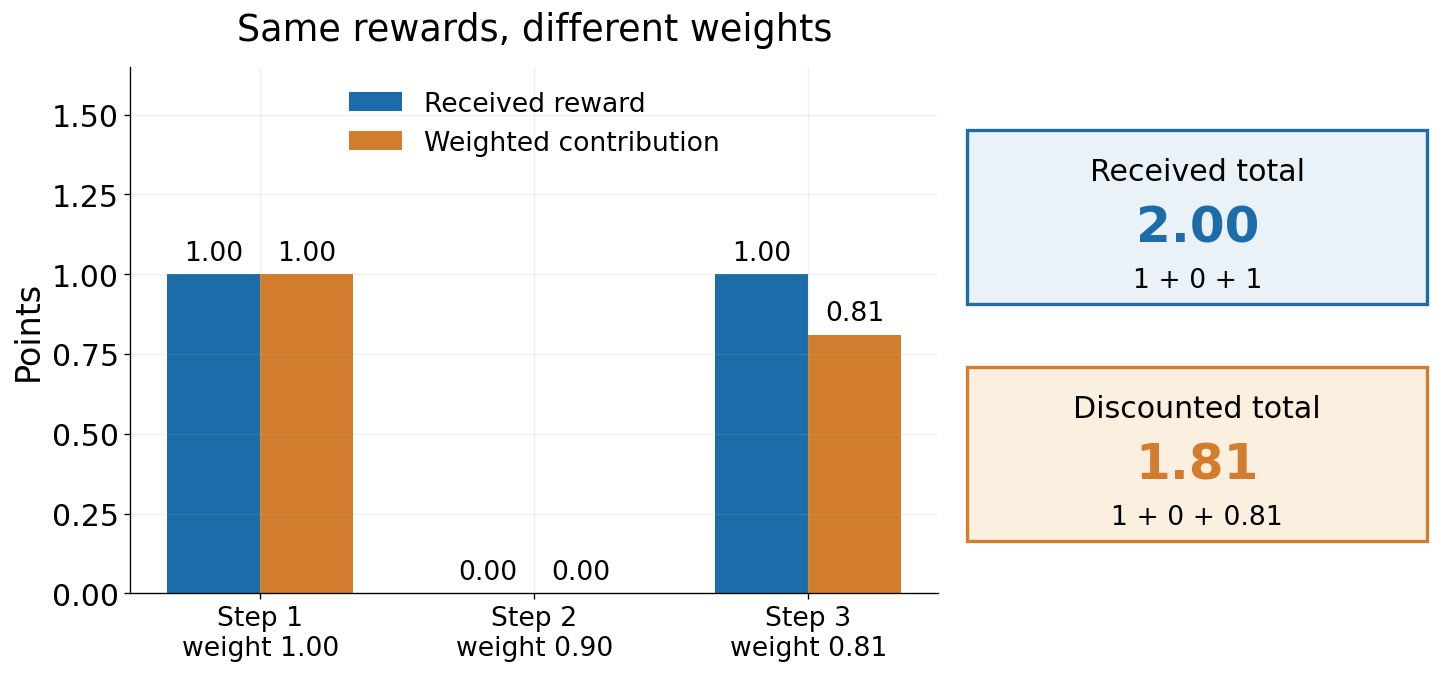

In [9]:
steps = np.arange(1, len(rewards) + 1)
discount_weights = GAMMA ** np.arange(len(rewards))
discounted_contributions = rewards * discount_weights
fig, (ax, summary_ax) = plt.subplots(
    1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1.65, 1]},
    layout="constrained")
width = 0.34
received_bars = ax.bar(steps - width / 2, rewards, width,
                       color=COLORS[0], label="Received reward")
weighted_bars = ax.bar(steps + width / 2, discounted_contributions, width,
                       color=COLORS[2], label="Weighted contribution")
ax.bar_label(received_bars, fmt="%.2f", padding=5, fontsize=16)
ax.bar_label(weighted_bars, fmt="%.2f", padding=5, fontsize=16)
ax.set(xticks=steps, xticklabels=[f"Step {t}\nweight {w:.2f}"
                                 for t, w in zip(steps, discount_weights)],
       ylim=(0, 1.65), ylabel="Points", title="Same rewards, different weights")
ax.tick_params(axis="x", labelsize=16)
ax.legend(loc="upper center", fontsize=16, frameon=False)
summary_ax.axis("off")
summary_ax.set(xlim=(0, 1), ylim=(0, 1))
for y, title, value, formula, color, face in [
    (0.55, "Received total", rewards.sum(), "1 + 0 + 1", COLORS[0], "#EAF2F8"),
    (0.10, "Discounted total", discounted_contributions.sum(), "1 + 0 + 0.81", COLORS[2], "#FBEFDF"),
]:
    summary_ax.add_patch(Rectangle((0.03, y), 0.94, 0.33,
                                   facecolor=face, edgecolor=color, linewidth=2))
    summary_ax.text(0.5, y + 0.25, title, ha="center", va="center", fontsize=18)
    summary_ax.text(0.5, y + 0.145, f"{value:.2f}", ha="center", va="center",
                    fontsize=30, color=color, fontweight="bold")
    summary_ax.text(0.5, y + 0.045, formula, ha="center", va="center", fontsize=16)
plt.show()


図 4：青い棒が実際にもらう点数、橙色の棒が開始時点から評価したときの寄与である。3 手目にもらう点数は 1 点のままだが、2 手先なので評価の重みは 0.81 になり、割引後の寄与は 0.81 点となる。実際の合計 2 点と、割引後の合計 1.81 点を分けて見る。


### ② 1 回の結果から、起こりうる結果の平均へ

今度は L1 から **2 手分だけ**数える。コインを 2 回投げるので、行動の組み合わせは次の 4 通りで、それぞれ同じ確率で起こる。

| 行動の順番 | 場所の変化 | 報酬の順番 | 割引した合計 |
|---|---|---|---:|
| 左 → 左 | L1 → L1 → L1 | −1, −1 | −1 ＋ 0.9 × (−1) ＝ **−1.90** |
| 左 → 右 | L1 → L1 → L2 | −1, ＋1 | −1 ＋ 0.9 × 1 ＝ **−0.10** |
| 右 → 左 | L1 → L2 → L1 | ＋1, 0 | 1 ＋ 0.9 × 0 ＝ **1.00** |
| 右 → 右 | L1 → L2 → L2 | ＋1, −1 | 1 ＋ 0.9 × (−1) ＝ **0.10** |

4 つの合計を足して 4 で割ると、**(−1.90 − 0.10 ＋ 1.00 ＋ 0.10) ÷ 4 ＝ −0.225 点**となる。

1 手目だけなら、壁の −1 点とリンゴの ＋1 点が半々なので平均は 0 点だった。**次の 1 手も含めると平均は −0.225 点になる**。その場の点数だけでは、先の点数まで含む評価はできない。


In [10]:
paths = []
for first_action in range(2):
    for second_action in range(2):
        middle_state = NEXT_STATE[0, first_action]
        first_reward = REWARD[0, first_action]
        second_reward = REWARD[middle_state, second_action]
        paths.append({
            "最初の行動": ACTION_NAMES[first_action],
            "次の行動": ACTION_NAMES[second_action],
            "1 手目の点数": first_reward, "2 手目の点数": second_reward,
            "起こる確率": 0.25,
            "2 手分の割引した合計": first_reward + GAMMA * second_reward,
        })
two_step_paths = pd.DataFrame(paths)
display(two_step_paths)
two_step_average = np.sum(two_step_paths["起こる確率"]
                          * two_step_paths["2 手分の割引した合計"])
print(f"L1 からの 2 手分の平均：{two_step_average:.3f} 点")
np.testing.assert_allclose(two_step_average, -0.225)


,最初の行動,次の行動,1 手目の点数,2 手目の点数,起こる確率,2 手分の割引した合計
0,Left,Left,-1.0,-1.0,0.25,-1.9
1,Left,Right,-1.0,1.0,0.25,-0.1
2,Right,Left,1.0,0.0,0.25,1.0
3,Right,Right,1.0,-1.0,0.25,0.1


L1 からの 2 手分の平均：-0.225 点


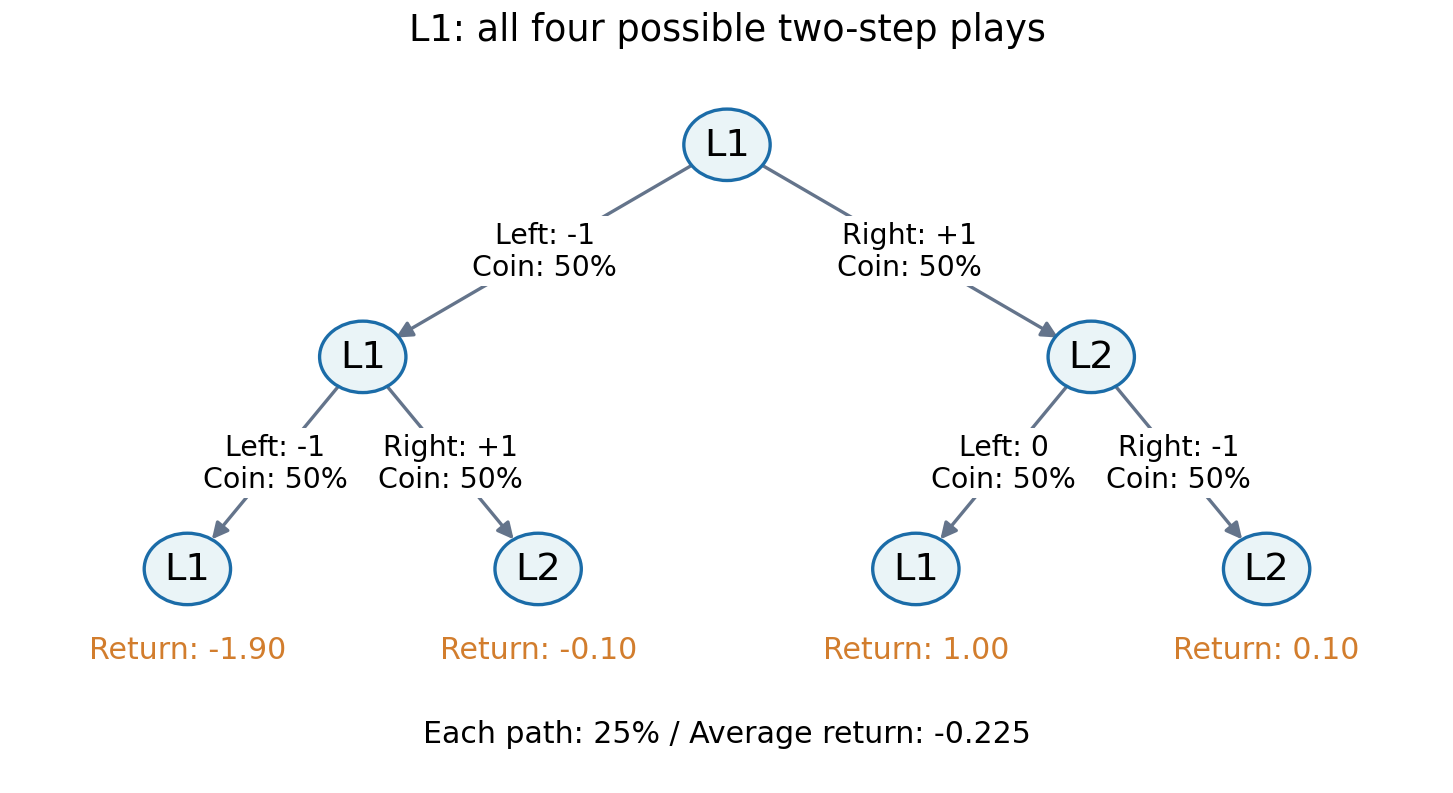

In [11]:
fig, ax = plt.subplots(figsize=(12, 6.5), layout="constrained")
ax.axis("off")
nodes = [(0, 4.3, "L1"), (-2.7, 2.4, "L1"), (2.7, 2.4, "L2"),
         (-4.0, 0.5, "L1"), (-1.4, 0.5, "L2"),
         (1.4, 0.5, "L1"), (4.0, 0.5, "L2")]
edges = [(0, 1, "Left: -1"), (0, 2, "Right: +1"),
         (1, 3, "Left: -1"), (1, 4, "Right: +1"),
         (2, 5, "Left: 0"), (2, 6, "Right: -1")]
for parent, child, label in edges:
    x1, y1, _ = nodes[parent]
    x2, y2, _ = nodes[child]
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), shrinkA=23, shrinkB=23,
                                arrowstyle="-|>", mutation_scale=20,
                                linewidth=2, color="#64748B"))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, label + "\nCoin: 50%",
            ha="center", va="center", fontsize=17,
            bbox=dict(facecolor="white", edgecolor="none", pad=3))
for x, y, label in nodes:
    ax.add_patch(Circle((x, y), 0.32, facecolor="#EAF4F7", edgecolor=COLORS[0], lw=2))
    ax.text(x, y, label, ha="center", va="center", fontsize=23)
for x, value in zip([-4.0, -1.4, 1.4, 4.0], [-1.9, -0.1, 1.0, 0.1]):
    ax.text(x, -0.3, f"Return: {value:.2f}", ha="center", fontsize=18,
            color=COLORS[2])
ax.text(0, -1.05, "Each path: 25% / Average return: -0.225",
        ha="center", fontsize=18)
ax.set(xlim=(-5.3, 5.3), ylim=(-1.4, 5.0),
       title="L1: all four possible two-step plays")
plt.show()


図 5：上から下へ 2 手進む。分岐の半分ずつという確率は、左右を決めるコインの確率である。行動を決めた後の移動先は、このゲームでは必ず 1 つに決まる。

### ③ 4 通りを「最初に左」と「最初に右」にまとめる

同じ平均を、最初の行動ごとに計算してみる。

| 最初の行動 | その後に起こる 2 通り | その 2 通りの平均 |
|---|---|---:|
| 左 | −1.90 点、−0.10 点 | **−1.00 点** |
| 右 | 1.00 点、0.10 点 | **0.55 点** |

最後にこの 2 つを半分ずつ足しても、**(−1.00 ＋ 0.55) ÷ 2 ＝ −0.225 点**になる。

さらに、左のグループは「今の壁の −1 点 ＋ L1 での残り 1 手の平均を 0.9 倍」と読める。L1 での残り 1 手は −1 点と ＋1 点が半々なので、その平均は 0 点である。

右のグループは「今のリンゴの ＋1 点 ＋ L2 での残り 1 手の平均を 0.9 倍」。L2 の 1 手の平均は (0 − 1) ÷ 2 ＝ −0.5 点なので、**1 ＋ 0.9 × (−0.5) ＝ 0.55 点**である。

このように、先の枝を全部書かずに**移動先からの平均点にまとめる**のが、ベルマン方程式の考え方である。2 手に限らず、その先も含めた平均点へ置き換えると、状態価値の式になる。


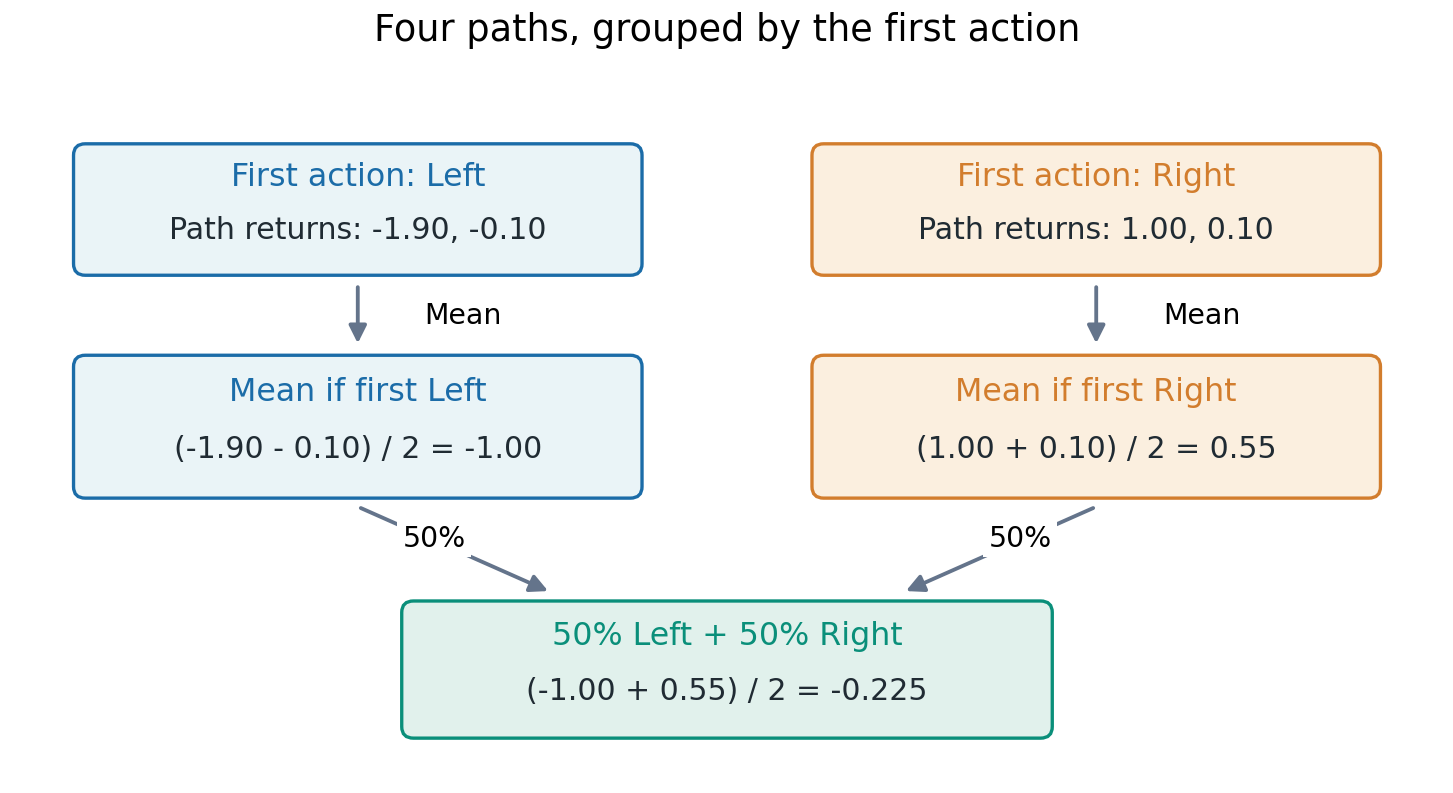

In [12]:
diagram_group_means = two_step_paths.groupby("最初の行動")["2 手分の割引した合計"].mean()
fig, ax = plt.subplots(figsize=(12, 6.5), layout="constrained")
ax.axis("off")
diagram_card(ax, 0.45, 3.8, 4.8, 1.1, "First action: Left",
             "Path returns: -1.90, -0.10")
diagram_card(ax, 6.75, 3.8, 4.8, 1.1, "First action: Right",
             "Path returns: 1.00, 0.10", face="#FBEFDF", edge=COLORS[2])
diagram_card(ax, 0.45, 1.85, 4.8, 1.2, "Mean if first Left",
             f"(-1.90 - 0.10) / 2 = {diagram_group_means['Left']:.2f}")
diagram_card(ax, 6.75, 1.85, 4.8, 1.2, "Mean if first Right",
             f"(1.00 + 0.10) / 2 = {diagram_group_means['Right']:.2f}",
             face="#FBEFDF", edge=COLORS[2])
diagram_arrow(ax, (2.85, 3.7), (2.85, 3.15), "Mean", (3.75, 3.43))
diagram_arrow(ax, (9.15, 3.7), (9.15, 3.15), "Mean", (10.05, 3.43))
diagram_card(ax, 3.25, -0.25, 5.5, 1.15, "50% Left + 50% Right",
             f"(-1.00 + 0.55) / 2 = {two_step_average:.3f}",
             face="#E1F1EC", edge=COLORS[1])
diagram_arrow(ax, (2.85, 1.75), (4.5, 1.0), "50%", (3.5, 1.48))
diagram_arrow(ax, (9.15, 1.75), (7.5, 1.0), "50%", (8.5, 1.48))
ax.set(xlim=(-0.1, 12.1), ylim=(-0.65, 5.6),
       title="Four paths, grouped by the first action")
plt.show()


図 6：上段の 4 つの結果を、まず「最初に左」と「最初に右」の中で平均する。次に、その 2 つの平均をコインの割合で半分ずつ混ぜる。最後の −0.225 点は、4 通りを一度に平均したときと同じである。平均をまとめ直しても答えは変わらない。


### ④ 「その場所からの続き」にまとめられる理由

L2 に着いたら、次は左へ戻るか、右の壁にぶつかるかをコインで決める。L2 に来る前にリンゴを何回取ったかによって、次の点数の規則やコインの確率は変わらない。

したがって、このゲームでは「今 L2 にいる」と分かれば、その先の平均点を L2 の分としてひとまとめにできる。これが、状態が将来を予測するのに十分な情報を持つ、というマルコフ性の具体例である。

もし「鍵を持っているときだけリンゴを取れる」というゲームなら、位置に加えて鍵の有無も状態に入れる必要がある。


<details>
<summary>補足：期待値とマルコフ性を使った詳しい導出</summary>

### 期待値を取り、次状態の価値に置き換える

状態価値関数の定義に、収益の再帰関係を代入する。

$$
\begin{aligned}
v_\pi(s)
&=\mathbb E_\pi[G_t\mid S_t=s]\\
&=\mathbb E_\pi[R_t+\gamma G_{t+1}\mid S_t=s].
\end{aligned}
$$

ここで、行動 $a$ は $\pi(a\mid s)$、その後の次状態 $s'$ は $p(s'\mid s,a)$ に従う。行動と次状態の全組み合わせで場合分けすると、

$$
v_\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}p(s'\mid s,a)
\mathbb E_\pi[R_t+\gamma G_{t+1}\mid S_t=s,A_t=a,S_{t+1}=s'].
$$

括弧の中の期待値は、線形性によって 2 つに分けられる。

$$
\mathbb E_\pi[R_t\mid s,a,s']
+\gamma\mathbb E_\pi[G_{t+1}\mid s,a,s'].
$$

第 1 項は報酬関数 $r(s,a,s')$ である。第 2 項では、MDP のマルコフ性により、次状態 $s'$ が分かればそれより前の状態・行動は将来の予測に必要ない。その後も同じ方策 $\pi$ に従うので、

$$\mathbb E_\pi[G_{t+1}\mid s,a,s']=v_\pi(s')$$

と置ける。**現在の報酬と将来の収益が独立だから、という理由ではない**。

</details>


### ⑤ 具体例の平均の取り方を、1 本の式にする

ここまでの「今の点数に、その先の平均を加える」を記号で書くと、

$$
\boxed{
v_\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}p(s'\mid s,a)
\left\{r(s,a,s')+\gamma v_\pi(s')\right\}
}
$$

これが**状態価値関数のベルマン方程式**である。

| 式の部分 | 読み方 |
|---|---|
| $r(s,a,s')$ | 今の遷移で受け取る報酬 |
| $\gamma v_\pi(s')$ | 次状態から先の価値を、1 ステップ割り引く |
| $\sum_{s'}p(s'\mid s,a)\{\cdots\}$ | 行動 $a$ の後に起こりうる遷移について平均する |
| $\sum_a\pi(a\mid s)(\cdots)$ | 現在状態で選びうる行動について平均する |

つまり、**現在状態の価値は、「現在の報酬＋割引した次状態の価値」を、方策と環境の確率で平均した値に等しい**。

図 5 の先の枝を、移動先からの平均点 $v_\pi(s')$ にまとめたと考える。和の記号 $\sum$ は、起こりうる場合について「掛けて足す」ことを表す。


> **3.1 のまとめ**：まず「今の点数」と「その先」を分ける。次に、左だった場合と右だった場合を、それぞれの確率で平均する。具体例の 4 通りをまとめた平均と、ベルマン方程式は同じ考え方でつながっている。


# 3.2 ベルマン方程式の例
## 3.2.1 2マスのグリッドワールド

ここからは、冒頭のゲームを **2 手だけで打ち切らず、その先も続ける場合**の平均点を求める。遊び方はこれまでと同じ、どちらの場所でもコインで左右を決める方策である。

L1 と L2 のそれぞれに「ここから遊び続けると、割引後に平均何点になるか」というメモを置くと考えよう。これが状態価値である。**L2 は終了状態ではなく、リンゴを取った後もゲームは続く**。


### 具体例：平均点を書いたメモを受け取ったら

まず答えを先に見て、何を表す数字かを確かめる。メモには **L1：−2.25 点、L2：−2.75 点**と書かれていたとする。この数字の求め方は、この後で説明する。

L1 で次の行動を選ぶ直前に、2 つの可能性を計算する。

| 最初にすること | 今もらう点数 | 移動先のメモ | 今の点数 ＋ メモを 0.9 倍 |
|---|---:|---:|---:|
| 左の壁に向かう | −1 | L1 の −2.25 | **−3.025** |
| 右へ進みリンゴを取る | ＋1 | L2 の −2.75 | **−1.475** |

コインで半々に選ぶので、2 つの平均は **(−3.025 − 1.475) ÷ 2 ＝ −2.25 点**。元の L1 のメモと同じになった。

L2 でも、左なら 0 ＋ 0.9 × (−2.25) ＝ −2.025 点、右なら −1 ＋ 0.9 × (−2.75) ＝ −3.475 点。その平均は **−2.75 点**で、L2 のメモと一致する。

ベルマン方程式で探すのは、このように**メモを使って 1 手先から計算し直しても、どの場所でも同じ数字に戻るようなメモ**である。数字は 1 回のプレイの実測点ではなく、同じ遊び方を続けるときの期待値である。


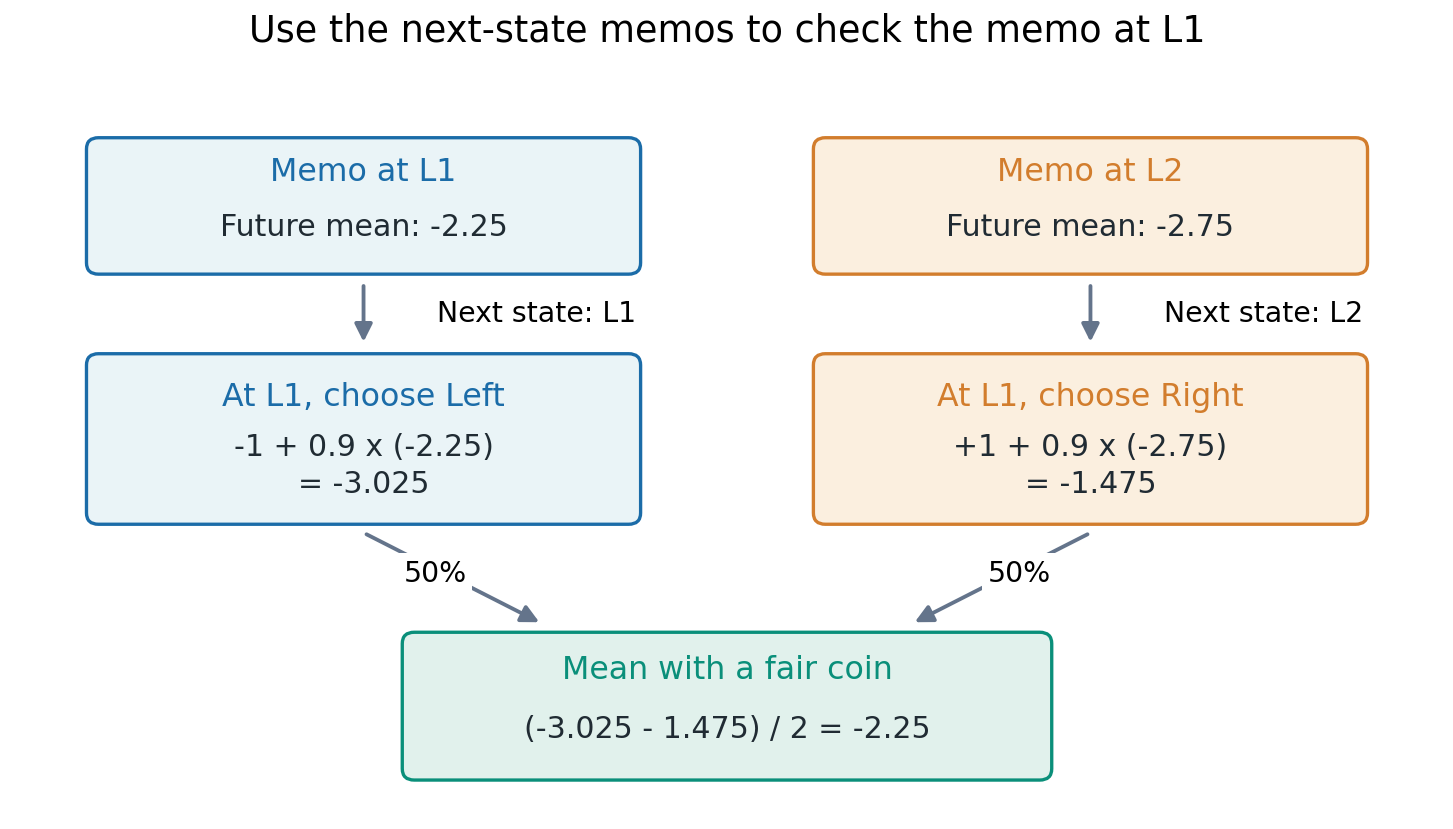

In [13]:
# この場所では本文と同じく答えのメモを先に置き、後のセルで連立方程式から求める。
diagram_memos = np.array([-2.25, -2.75])
diagram_left = -1 + GAMMA * diagram_memos[0]
diagram_right = 1 + GAMMA * diagram_memos[1]
fig, ax = plt.subplots(figsize=(12, 6.8), layout="constrained")
ax.axis("off")
diagram_card(ax, 0.65, 3.75, 4.6, 1.15, "Memo at L1", "Future mean: -2.25")
diagram_card(ax, 6.75, 3.75, 4.6, 1.15, "Memo at L2", "Future mean: -2.75",
             face="#FBEFDF", edge=COLORS[2])
diagram_card(ax, 0.65, 1.55, 4.6, 1.45, "At L1, choose Left",
             f"-1 + 0.9 x (-2.25)\n= {diagram_left:.3f}")
diagram_card(ax, 6.75, 1.55, 4.6, 1.45, "At L1, choose Right",
             f"+1 + 0.9 x (-2.75)\n= {diagram_right:.3f}",
             face="#FBEFDF", edge=COLORS[2])
diagram_arrow(ax, (2.95, 3.65), (2.95, 3.1), "Next state: L1", (4.4, 3.38))
diagram_arrow(ax, (9.05, 3.65), (9.05, 3.1), "Next state: L2", (10.5, 3.38))
diagram_card(ax, 3.3, -0.7, 5.4, 1.25, "Mean with a fair coin",
             f"(-3.025 - 1.475) / 2 = {0.5 * (diagram_left + diagram_right):.2f}",
             face="#E1F1EC", edge=COLORS[1])
diagram_arrow(ax, (2.95, 1.45), (4.45, 0.65), "50%", (3.55, 1.1))
diagram_arrow(ax, (9.05, 1.45), (7.55, 0.65), "50%", (8.45, 1.1))
ax.set(xlim=(0, 12), ylim=(-1.05, 5.55),
       title="Use the next-state memos to check the memo at L1")
plt.show()


図 7：上の 2 枚が「その場所から先の平均点」を書いたメモである。L1 で左へ進む場合は L1 のメモ、右へ進む場合は L2 のメモを使う。今の点数を足してから半分ずつ混ぜると、下の −2.25 点になり、元の L1 のメモに戻る。この図の矢印は、計算でどのメモを使うかを示す。メモの値は本文と同じく先に示した答えであり、続くセルで求める。


### まだ分からないメモの中身を、式で表す

L1 のメモを $v_\pi(L1)$、L2 のメモを $v_\pi(L2)$ と書く。どちらのメモも先の計算で再現されるように式を立てる。

まず $L1$ から考える。左なら報酬 $-1$ を得て $L1$ に残り、右なら報酬 $+1$ を得て $L2$ に移る。したがって、

$$
v_\pi(L1)=\frac12\{-1+\gamma v_\pi(L1)\}
+\frac12\{1+\gamma v_\pi(L2)\}.
$$

同様に、$L2$ では、

$$
v_\pi(L2)=\frac12\{0+\gamma v_\pi(L1)\}
+\frac12\{-1+\gamma v_\pi(L2)\}.
$$

各式の外側にある $1/2$ は行動を選ぶ確率である。環境の遷移確率は、選んだ行動に対応する次状態で 1 なので、式から省略している。


### 2 本の連立方程式を解く

$v_1=v_\pi(L1)$、$v_2=v_\pi(L2)$ と置き、$\gamma=0.9$ を代入すると、

$$
\begin{aligned}
v_1&=0.45v_1+0.45v_2,\\
v_2&=-0.5+0.45v_1+0.45v_2.
\end{aligned}
$$

下の式から上の式を引くと $v_2-v_1=-0.5$。これを上の式に代入して、

$$
v_1=0.45v_1+0.45(v_1-0.5)=0.9v_1-0.225,
$$

$$\boxed{v_\pi(L1)=-2.25,\qquad v_\pi(L2)=-2.75}.$$


2 枚のメモを同時に使うのは、L1 から L2 にも、L2 から L1 にも進めるからである。両方の場所で計算が合う数字を求めている。


<details>
<summary>補足：連立方程式を行列で書く方法と NumPy の計算</summary>

同じ連立方程式を、行列では次のように書ける。

$$
\begin{pmatrix}0.55&-0.45\\-0.45&0.55\end{pmatrix}
\begin{pmatrix}v_1\\v_2\end{pmatrix}
=\begin{pmatrix}0\\-0.5\end{pmatrix}.
$$

コードでは、方策に従ったときの次状態の確率を $P_\pi$、直後の期待報酬を $r_\pi$ にまとめる。

$$
P_\pi(s,s')=\sum_a\pi(a\mid s)p(s'\mid s,a),\qquad
r_\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}p(s'\mid s,a)r(s,a,s').
$$

すると $v_\pi=r_\pi+\gamma P_\pi v_\pi$、すなわち $(I-\gamma P_\pi)v_\pi=r_\pi$ となる。$I$ は対角成分が 1、それ以外が 0 の単位行列である。

</details>


In [14]:
# ゲームのルールから連立方程式を作る。詳しい行列の説明は上の補足にある。
P_pi = np.zeros((2, 2))
for s in range(2):
    for a in range(2):
        s_next = NEXT_STATE[s, a]
        P_pi[s, s_next] += POLICY[s, a]
r_pi = (POLICY * REWARD).sum(axis=1)
coefficient = np.eye(2) - GAMMA * P_pi
v_pi = np.linalg.solve(coefficient, r_pi)

display(pd.DataFrame({"今いる場所": STATE_NAMES, "平均点のメモ（状態価値）": v_pi}))
np.testing.assert_allclose(P_pi.sum(axis=1), 1.0)
np.testing.assert_allclose(v_pi, [-2.25, -2.75])


,今いる場所,平均点のメモ（状態価値）
0,L1,-2.25
1,L2,-2.75


### マイナスの平均点は何を意味する？

リンゴを取ると ＋1 点でも、コイン任せでは壁にぶつかることも多い。そのため、先まで続けた割引後の平均はマイナスになる。L1 のメモが −2.25 点というのは「始めた瞬間に 2.25 点を失う」という意味ではなく、そこから先の報酬をまとめて見積もった結果である。

L1 の直後の期待報酬は 0 点だったが、その先の期待報酬も含めると −2.25 点になる。次の表では、求めたメモを使って計算し直している。


In [15]:
discounted_next_value = GAMMA * (P_pi @ v_pi)
bellman_rhs = r_pi + discounted_next_value
display(pd.DataFrame({
    "元のメモ": v_pi, "今の 1 手の平均点": r_pi,
    "移動先のメモの平均を 0.9 倍": discounted_next_value,
    "計算し直したメモ": bellman_rhs, "元のメモとの差": v_pi - bellman_rhs,
}, index=STATE_NAMES))
np.testing.assert_allclose(v_pi, bellman_rhs, atol=1e-12)


,元のメモ,今の 1 手の平均点,移動先のメモの平均を 0.9 倍,計算し直したメモ,元のメモとの差
L1,-2.25,0.0,-2.25,-2.25,0.0
L2,-2.75,-0.5,-2.25,-2.75,0.0


## 3.2.2 ベルマン方程式の意義

2 手先までは、図 5 に 4 本の経路を描けばよかった。3 手なら 8 本、10 手なら 1,024 本、20 手なら 1,048,576 本になる。すべての経路を書き続けるのは大変である。

ところが、どの経路で来ても L1 からの続きは L1 のメモ、L2 からの続きは L2 のメモにまとめられる。今回なら、**2 枚のメモが互いに矛盾しないようにすればよい**。これが、無限に続く将来を 1 手先との関係にまとめる利点である。

この計算では、ゲームのルールと、コインで行動する確率が分かっている。ルールが分からなければ、それを経験から調べることも必要になる。

### 具体例：何手先まで数えるかを増やしてみる

今までに確かめた L1 の平均点は、1 手だけなら 0 点、2 手なら −0.225 点だった。では、5 手、10 手、100 手まで含めたらどう変わるだろうか。

次の計算では、前に求めた「残りの平均点」を使って、1 手ずつ先まで数える。数えなかった先は合計に含めない。2 手分の結果が、全 4 通りを数えた結果と同じになることも確認する。


In [16]:
HORIZON = 100
finite_values = np.zeros((HORIZON + 1, 2))
for h in range(1, HORIZON + 1):
    finite_values[h] = r_pi + GAMMA * (P_pi @ finite_values[h - 1])

selected = np.array([0, 1, 2, 5, 10, 30, 100])
display(pd.DataFrame({
    "含めるステップ数 h": selected,
    "L1 の有限価値": finite_values[selected, 0],
    "L2 の有限価値": finite_values[selected, 1],
    "無限の価値との最大誤差": np.abs(finite_values[selected] - v_pi).max(axis=1),
}))

# |R_t| <= 1 なので、含めなかった将来の絶対値は gamma**h / (1-gamma) 以下。
tail_bounds = GAMMA ** np.arange(HORIZON + 1) / (1 - GAMMA)
errors = np.abs(finite_values - v_pi).max(axis=1)
assert np.all(errors <= tail_bounds + 1e-12)
np.testing.assert_allclose(finite_values[2, 0], two_step_average)
print("100 ステップでの打ち切り誤差の上限：", f"{tail_bounds[-1]:.6f}")


,含めるステップ数 h,L1 の有限価値,L2 の有限価値,無限の価値との最大誤差
0,0,0.000000,0.000000,2.750000
1,1,0.000000,-0.500000,2.250000
2,2,-0.225000,-0.725000,2.025000
3,5,-0.773775,-1.273775,1.476225
4,10,-1.378304,-1.878304,0.871696
5,30,-2.144022,-2.644022,0.105978
6,100,-2.249934,-2.749934,0.000066


100 ステップでの打ち切り誤差の上限： 0.000266


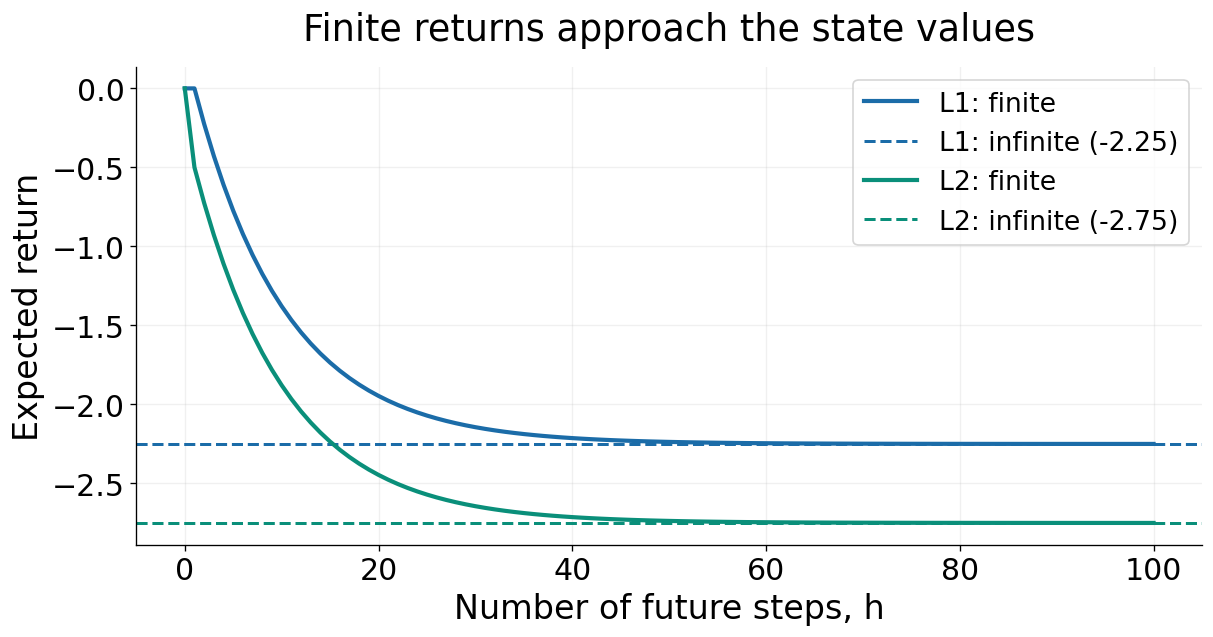

In [17]:
fig, ax = plt.subplots(figsize=(10, 5.2), layout="constrained")
for s, color in enumerate(COLORS[:2]):
    ax.plot(np.arange(HORIZON + 1), finite_values[:, s], color=color,
            linewidth=2.5, label=f"{STATE_NAMES[s]}: finite")
    ax.axhline(v_pi[s], color=color, linestyle="--", linewidth=1.8,
               label=f"{STATE_NAMES[s]}: infinite ({v_pi[s]:.2f})")
ax.set(xlabel="Number of future steps, h", ylabel="Expected return",
       title="Finite returns approach the state values")
ax.legend(loc="upper right")
plt.show()


図 8：実線は「その手数まで数えた平均点」、破線は先まで続ける場合のメモである。手数を増やすと、L1 は −2.25 点、L2 は −2.75 点へ近づいていく。

100 手の計算で打ち切るのは、記録する範囲を決めただけである。ゲームの終了条件が変わったわけではない。

> **3.2 のまとめ**：すべてのプレイを最後まで書く代わりに、各場所から先の平均をメモにまとめる。どの場所でも「今の点数＋移動先のメモを割り引いたもの」の平均と一致するように、メモの数字を求める。


<details>
<summary>補足：有限の将来の計算式と、打ち切り誤差</summary>

残り $h$ ステップだけ含める期待収益を $v_\pi^{(h)}$ とすると、$v_\pi^{(0)}=0$、

$$v_\pi^{(h)}=r_\pi+\gamma P_\pi v_\pi^{(h-1)}$$

となる。$h$ は「何手先まで含めるか」であり、軌跡上の時刻ではない。報酬の絶対値が 1 以下なら、含めなかった先の寄与は、

$$|v_\pi(s)-v_\pi^{(h)}(s)|\leq\frac{\gamma^h}{1-\gamma}$$

で抑えられる。$\gamma=0.9$、$h=100$ では、上限は約 0.000266 点である。

</details>


# 3.3 行動価値関数とベルマン方程式
## 3.3.1 行動価値関数

### 具体例：似ている 3 つの質問を分ける

| 質問 | 何を数えるか | 今回の答え |
|---|---|---:|
| L1 から右へ進んでリンゴを取った。この 1 手で何点もらう？ | **報酬**：その手の点数 | ＋1 点 |
| L1 から、最初もその後もコイン任せで遊ぶと平均何点？ | **状態価値**：その場所から先の平均点 | −2.25 点 |
| L1 で、最初だけ右と決め、その後はコイン任せなら平均何点？ | **行動価値**：最初の行動を決めた場合の平均点 | −1.475 点 |

「今リンゴを取ると 1 点もらう」と「その後まで含めて得か」は別の質問である。また、最初だけ右と決める場合は、最初からコイン任せの場合とも平均が異なる。

状態価値は $v_\pi(s)$、行動価値は $q_\pi(s,a)$ と書く。行動価値では、**最初の行動だけを指定し、次の状態からは方策 $\pi$ に従う**。

第 1 章のバンディットでは、その場の期待報酬を行動価値と呼んだ。MDP では、行動の後にもゲームが続くので、その先の報酬を含めている。


<details>
<summary>補足：行動価値の定義</summary>

$$q_\pi(s,a)=\mathbb E_\pi[G_t\mid S_t=s,A_t=a].$$

状態 $s$ と最初の行動 $a$ を決め、その後は同じ方策 $\pi$ に従ったときの期待収益である。方策が確率 0 を割り当てる行動でも、「最初にその行動を実行したら」と考えることで評価できる。

</details>


### 具体例：最初に右を選ぶ場合の見積もり

L1 で右へ進むと、今のリンゴで **＋1 点**を得て、L2 に着く。そこからコイン任せで続けた平均は、L2 のメモにある **−2.75 点**である。

L2 に着くのは 1 手後なので、そのメモを 0.9 倍して足す。

$$1+0.9\times(-2.75)=-1.475.$$

これが「L1 で最初だけ右を選ぶ」行動価値になる。L1 のメモ −2.25 点より高いのは、最初の壁への行動を避け、必ずリンゴを取ることにしたからである。その後の遊び方は変えていない。

ほかの 3 つの組み合わせも、同じように「今の点数＋移動先のメモを 0.9 倍」で計算できる。


In [18]:
# v_pi[NEXT_STATE] は、各 (状態, 行動) の遷移先の価値を並べた (2, 2) 配列。
next_values = v_pi[NEXT_STATE]
q_pi = REWARD + GAMMA * next_values

rows = []
for s in range(2):
    for a in range(2):
        rows.append({
            "状態": STATE_NAMES[s], "最初の行動": ACTION_NAMES[a],
            "次状態": STATE_NAMES[NEXT_STATE[s, a]], "直後の報酬": REWARD[s, a],
            "次状態の価値": next_values[s, a],
            "割引した次状態の価値": GAMMA * next_values[s, a],
            "行動価値 q_pi": q_pi[s, a],
        })
display(pd.DataFrame(rows))
np.testing.assert_allclose(q_pi, [[-3.025, -1.475], [-2.025, -3.475]])


,状態,最初の行動,次状態,直後の報酬,次状態の価値,割引した次状態の価値,行動価値 q_pi
0,L1,Left,L1,-1.0,-2.25,-2.025,-3.025
1,L1,Right,L2,1.0,-2.75,-2.475,-1.475
2,L2,Left,L1,0.0,-2.25,-2.025,-2.025
3,L2,Right,L2,-1.0,-2.75,-2.475,-3.475


### 具体例：「最初だけ右」と「ずっと右」はどこで違う？

**最初だけ右**なら、L1 → L2 でリンゴの ＋1 点を得た後、コインで行動する。次の手は、左へ戻って 0 点か、右の壁で −1 点かが半々になる。2 手だけ数えた平均は **1 ＋ 0.9 × (−0.5) ＝ 0.55 点**である。

**ずっと右**なら、最初のリンゴの後は L2 の右の壁へぶつかり続ける。報酬の並びは **＋1, −1, −1, −1, …**。2 手だけなら **0.10 点**で、先まで続けた割引後の合計は **−8 点**になる。

同じ「最初は右」でも、その後の行動が違うので値も異なる。次の表では、数える長さもそろえて比べている。


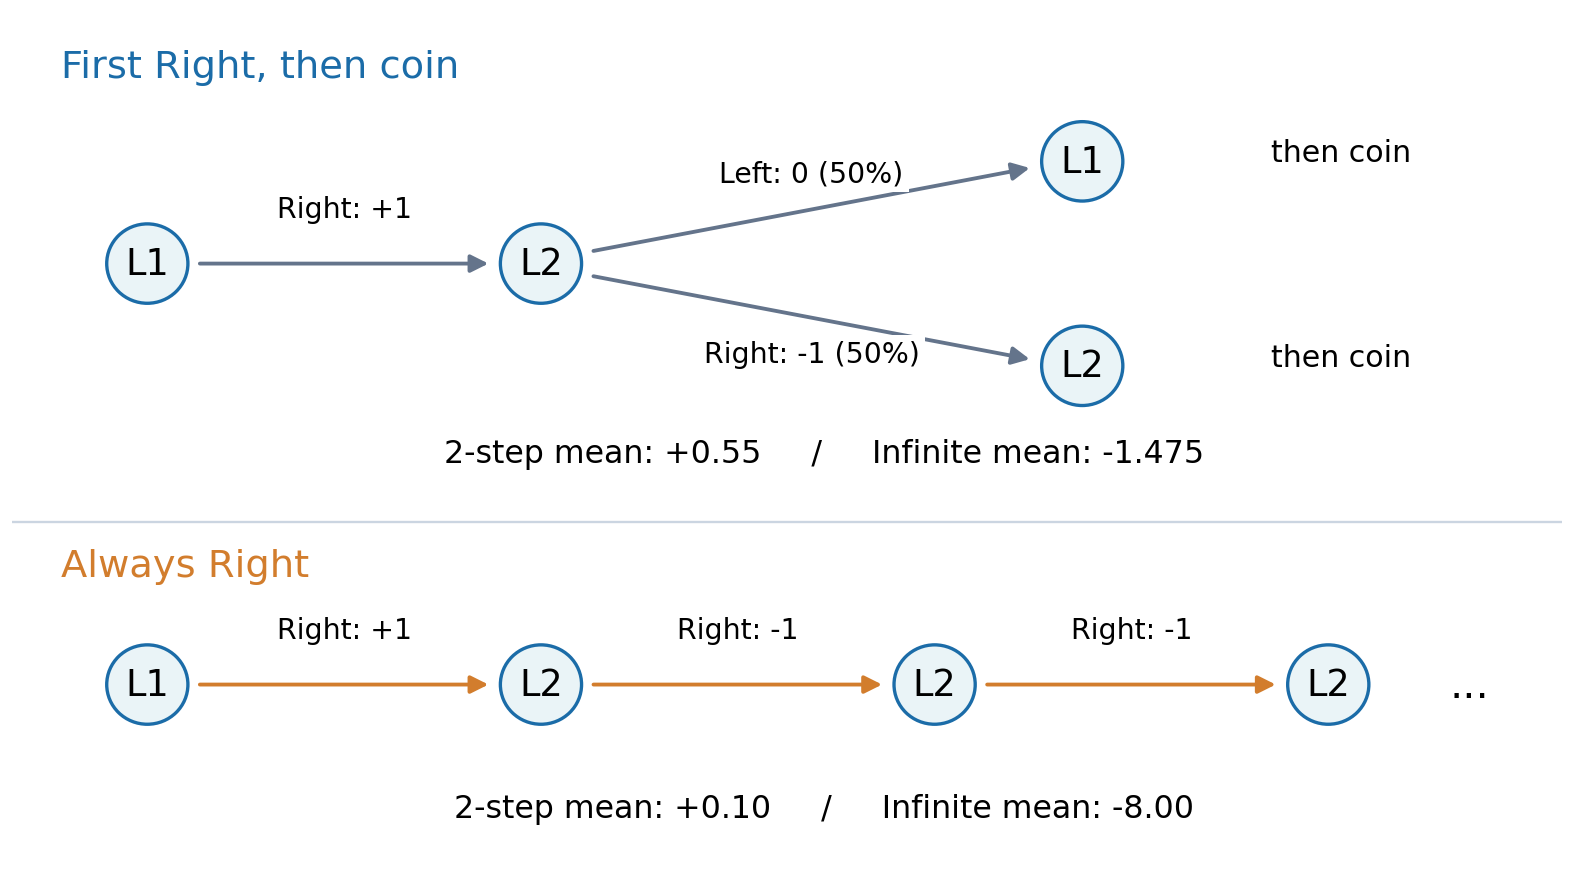

In [19]:
diagram_always_right = 1 - GAMMA / (1 - GAMMA)
fig, ax = plt.subplots(figsize=(13, 7.3), layout="constrained")
ax.axis("off")
ax.text(0.1, 6.55, "First Right, then coin", fontsize=23, color=COLORS[0])
for xy, name in [((0.8, 5.0), "L1"), ((4, 5.0), "L2"),
                 ((8.4, 5.85), "L1"), ((8.4, 4.15), "L2")]:
    diagram_state(ax, xy, name)
diagram_arrow(ax, (1.2, 5), (3.6, 5), "Right: +1", (2.4, 5.45))
diagram_arrow(ax, (4.4, 5.1), (8.0, 5.8), "Left: 0 (50%)", (6.2, 5.75))
diagram_arrow(ax, (4.4, 4.9), (8.0, 4.2), "Right: -1 (50%)", (6.2, 4.25))
ax.text(10.5, 5.85, "then coin", ha="center", fontsize=18)
ax.text(10.5, 4.15, "then coin", ha="center", fontsize=18)
ax.text(6.3, 3.35, f"2-step mean: +0.55     /     Infinite mean: {q_pi[0, 1]:.3f}",
        ha="center", fontsize=19)
ax.axhline(2.85, color="#CBD5E1", linewidth=1.4)
ax.text(0.1, 2.4, "Always Right", fontsize=23, color=COLORS[2])
for xy, name in [((0.8, 1.5), "L1"), ((4, 1.5), "L2"),
                 ((7.2, 1.5), "L2"), ((10.4, 1.5), "L2")]:
    diagram_state(ax, xy, name)
for start, end, label in [((1.2, 1.5), (3.6, 1.5), "Right: +1"),
                          ((4.4, 1.5), (6.8, 1.5), "Right: -1"),
                          ((7.6, 1.5), (10.0, 1.5), "Right: -1")]:
    diagram_arrow(ax, start, end, label,
                  ((start[0] + end[0]) / 2, 1.95), color=COLORS[2])
ax.text(11.55, 1.5, "...", ha="center", va="center", fontsize=25)
ax.text(6.3, 0.4, f"2-step mean: +0.10     /     Infinite mean: {diagram_always_right:.2f}",
        ha="center", fontsize=19)
ax.set(xlim=(-0.3, 12.3), ylim=(-0.1, 7.1))
plt.show()


図 9：上も下も、最初の右でリンゴの ＋1 点を得る。違いは 2 手目からである。上はコインで分岐し、左へ戻ることもあるが、下は右の壁で −1 点を受け続ける。2 手だけの値と、その先も続ける値を分けて比べよう。行動価値 −1.475 点が表すのは上の遊び方である。


In [20]:
first_right_rows = two_step_paths["最初の行動"] == "Right"
first_right_two_steps = two_step_paths.loc[first_right_rows, "2 手分の割引した合計"].mean()
always_right_two_steps = REWARD[0, 1] + GAMMA * REWARD[1, 1]
# 最初の +1 の後、壁の -1 が無限に続く割引和。
always_right_infinite = 1 - GAMMA / (1 - GAMMA)

display(pd.DataFrame({
    "遊び方": ["最初もその後もコイン任せ", "最初だけ右、その後はコイン任せ", "最初もその後も右"],
    "2 手分だけの平均": [two_step_average, first_right_two_steps, always_right_two_steps],
    "その先も続けた平均": [v_pi[0], q_pi[0, 1], always_right_infinite],
}))
np.testing.assert_allclose([first_right_two_steps, always_right_two_steps,
                           always_right_infinite], [0.55, 0.1, -8.0])


,遊び方,2 手分だけの平均,その先も続けた平均
0,最初もその後もコイン任せ,-0.225,-2.250
1,最初だけ右、その後はコイン任せ,0.550,-1.475
2,最初もその後も右,0.100,-8.000


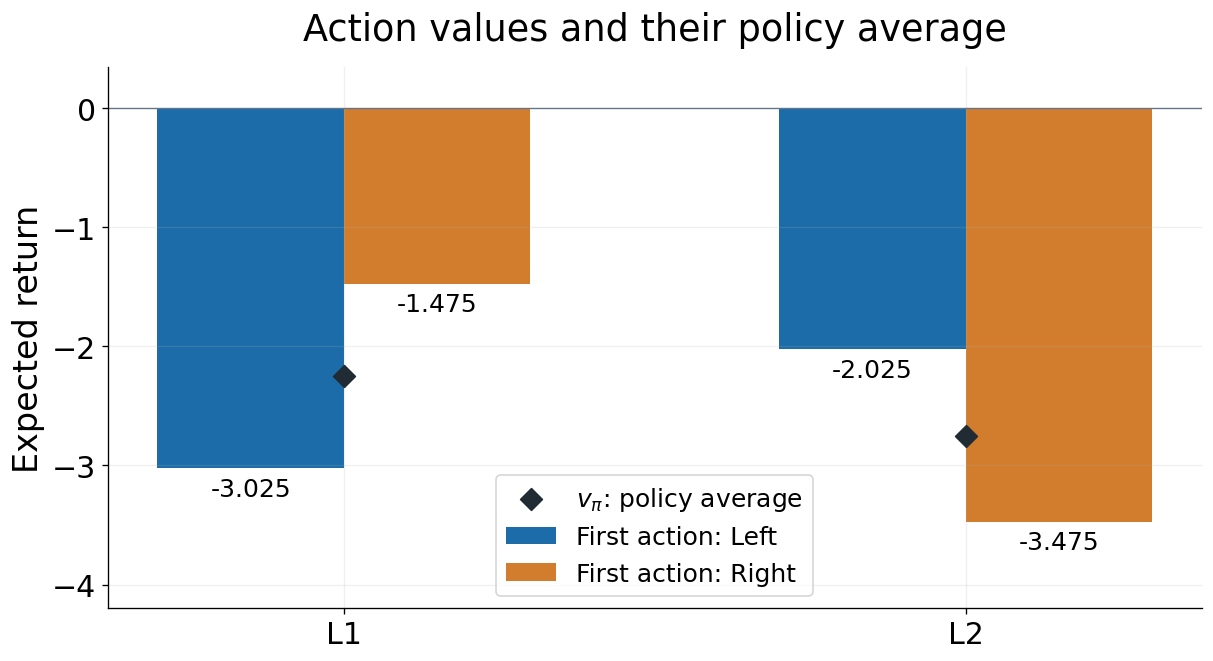

In [21]:
fig, ax = plt.subplots(figsize=(10, 5.4), layout="constrained")
x = np.arange(2)
width = 0.3
for a, color in enumerate([COLORS[0], COLORS[2]]):
    bars = ax.bar(x + (a - 0.5) * width, q_pi[:, a], width,
                  color=color, label=f"First action: {ACTION_NAMES[a]}")
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=15)
ax.scatter(x, v_pi, marker="D", color="#202B33", s=85, zorder=5,
           label=r"$v_\pi$: policy average")
ax.axhline(0, color="#64748B", linewidth=0.8)
ax.set(xticks=x, xticklabels=STATE_NAMES, ylabel="Expected return",
       ylim=(-4.2, 0.35), title="Action values and their policy average")
ax.legend(loc="lower center", ncol=1, fontsize=15)
plt.show()


図 10：棒は最初の行動を固定した行動価値、黒い菱形は状態価値である。状態価値は 2 本の棒の間にある。今回は左右を同じ確率で選ぶので、ちょうど中間になる。

$L2$ では、左を選ぶと直後の報酬は 0 だが、右を選ぶより行動価値が高い。直後の報酬だけでなく、次状態から先の価値まで加えたことで、将来を含む比較ができる。

ここで比べたのは、どちらも**最初の行動の後は同じランダム方策に従う場合**である。方策全体を変更した場合の価値は、その新しい方策について評価し直す必要がある。


<details>
<summary>補足：次状態の価値を使って行動価値を書く</summary>

$$q_\pi(s,a)=\sum_{s'}p(s'\mid s,a)\{r(s,a,s')+\gamma v_\pi(s')\}.$$

最初の行動は決まっているので、現在の行動については平均しない。次状態がランダムなら、起こりうる次状態の確率を掛けて足す。このゲームでは移動先が 1 つに決まるので、「今の点数＋割引した移動先のメモ」の 1 項だけになる。

</details>


## 3.3.2 行動価値関数を使ったベルマン方程式
### 具体例：2 つの行動の見積もりを、コインの割合で混ぜる

L1 で「最初に左」の場合の見積もりは −3.025 点、「最初に右」なら −1.475 点だった。

最初の行動をコインで決めると、この 2 つが半々になる。たとえば 100 回始める場合、左から始まる 50 回と、右から始まる 50 回を目安に、その後まで含めた期待点数を見積もる。

**50 × (−3.025) ＋ 50 × (−1.475) ＝ −225 点**。1 回あたりに戻すと **−2.25 点**で、L1 の状態価値と同じになる。50 回ずつというのは確率から考えた回数の目安で、実際には変動する。

この関係を記号で書くと、

$$v_\pi(s)=\sum_a\pi(a\mid s)q_\pi(s,a).$$

つまり、**最初の行動を決めた場合の平均点を、実際にその行動を選ぶ確率で混ぜると、その場所からの平均点に戻る**。左右の確率が違うときは、半分ずつではなく、その確率で重み付けする。


In [22]:
# POLICY と q_pi はどちらも (状態, 行動)。行動の軸 axis=1 を足す。
v_from_q = (POLICY * q_pi).sum(axis=1)
display(pd.DataFrame({
    "連立方程式で求めた v_pi": v_pi,
    "行動価値を方策で平均した値": v_from_q,
    "差": v_pi - v_from_q,
}, index=STATE_NAMES))
np.testing.assert_allclose(v_from_q, v_pi, atol=1e-12)


,連立方程式で求めた v_pi,行動価値を方策で平均した値,差
L1,-2.25,-2.25,0.0
L2,-2.75,-2.75,0.0


### 具体例：移動先のメモを、さらに次の行動に分ける

L1 から右へ進んだ後の L2 のメモ −2.75 点は、次の 2 つの見積もりを平均したものでもある。

| L2 に着いた後の行動 | そこから先の見積もり |
|---|---:|
| 左を選び、その後はコイン任せ | −2.025 点 |
| 右を選び、その後はコイン任せ | −3.475 点 |
| 半分ずつの平均 | **−2.75 点** |

そのため、最初のリンゴの ＋1 点に、この 2 つの平均を 0.9 倍して足しても、同じ答えになる。

$$1+0.9\times\frac{-2.025-3.475}{2}=-1.475.$$

これが、**今の行動の見積もりを、次の場所で選ぶ行動の見積もりへ結び付ける**、行動価値関数のベルマン方程式の具体例である。

最初の右はすでに指定した行動なので、そこで半分にはしない。平均するのは、L2 に着いた後にコインで選ぶ行動である。


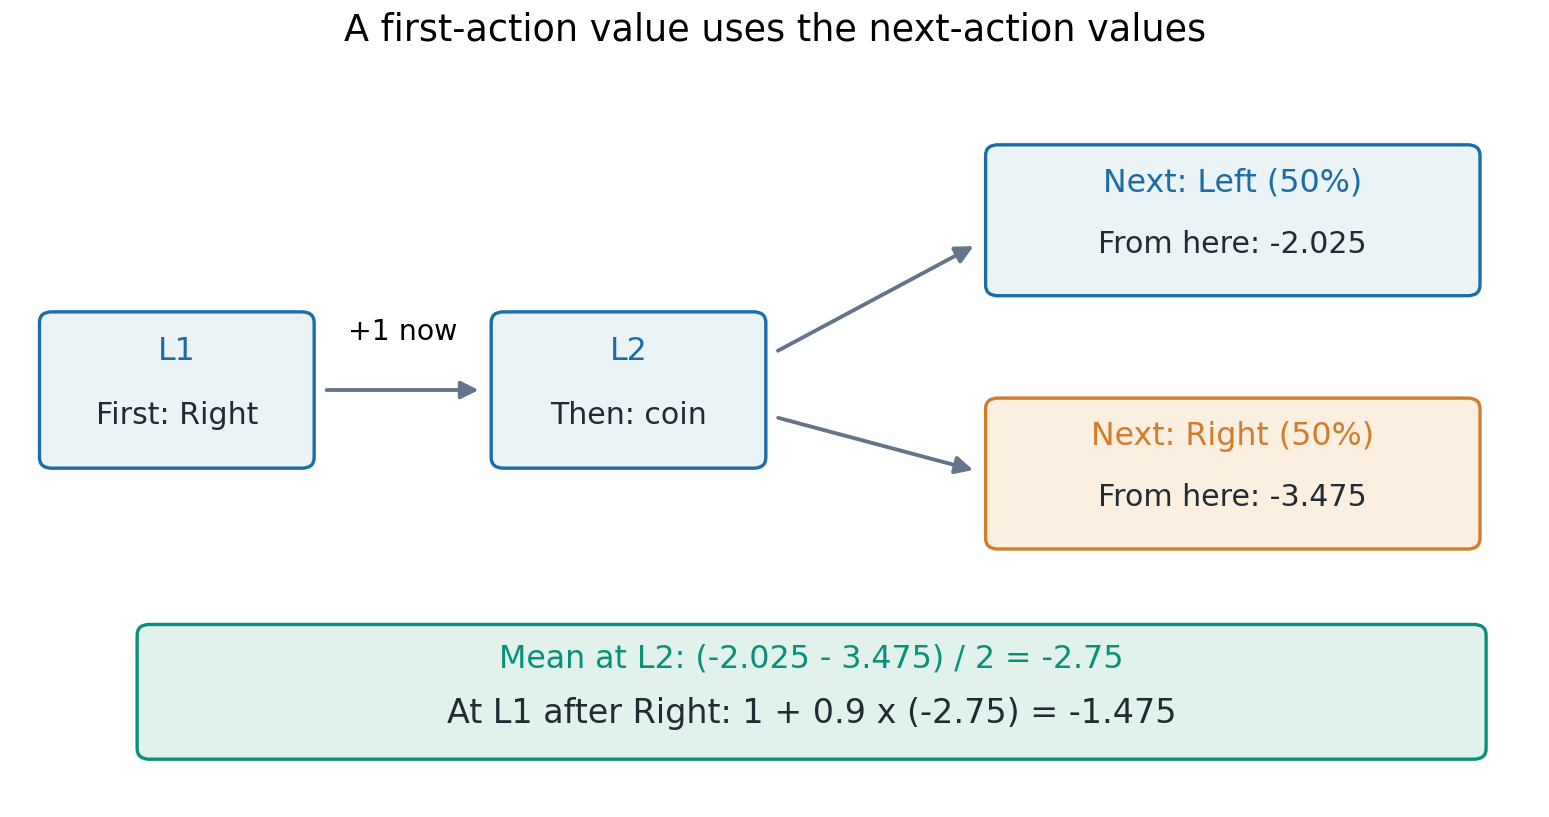

In [23]:
diagram_next_action_mean = np.sum(POLICY[1] * q_pi[1])
diagram_first_right_value = 1 + GAMMA * diagram_next_action_mean
fig, ax = plt.subplots(figsize=(12.8, 6.7), layout="constrained")
ax.axis("off")
diagram_card(ax, 0.15, 2.4, 2.2, 1.4, "L1", "First: Right")
diagram_card(ax, 3.85, 2.4, 2.2, 1.4, "L2", "Then: coin")
diagram_card(ax, 7.9, 4.0, 4.0, 1.35, "Next: Left (50%)",
             f"From here: {q_pi[1, 0]:.3f}")
diagram_card(ax, 7.9, 1.65, 4.0, 1.35, "Next: Right (50%)",
             f"From here: {q_pi[1, 1]:.3f}", face="#FBEFDF", edge=COLORS[2])
diagram_arrow(ax, (2.45, 3.1), (3.75, 3.1), "+1 now", (3.1, 3.65))
diagram_arrow(ax, (6.15, 3.45), (7.8, 4.45))
diagram_arrow(ax, (6.15, 2.85), (7.8, 2.35))
diagram_card(ax, 0.95, -0.3, 11, 1.2,
             f"Mean at L2: (-2.025 - 3.475) / 2 = {diagram_next_action_mean:.2f}",
             f"At L1 after Right: 1 + 0.9 x (-2.75) = {diagram_first_right_value:.3f}",
             face="#E1F1EC", edge=COLORS[1], title_size=19, body_size=20)
ax.set(xlim=(-0.1, 12.4), ylim=(-0.75, 6.1),
       title="A first-action value uses the next-action values")
plt.show()


図 11：最初の右は決めているので、L1 から L2 までの矢印には半分の確率を掛けない。半分ずつ平均するのは、L2 に着いてから選ぶ左と右である。右端の数値はその 1 手の報酬ではなく、その行動の後まで含めた見積もりなので、先の報酬をもう一度足す必要はない。2 つを平均した −2.75 点を 0.9 倍し、最初のリンゴの 1 点を加えると −1.475 点になる。


<details>
<summary>補足：行動価値どうしを結ぶベルマン方程式の導出</summary>

### 行動価値どうしを結ぶベルマン方程式

先ほどの関係を使うと、$q_\pi$ の式から $v_\pi$ を消せる。次状態 $s'$ では次の行動 $a'$ を $\pi(a'\mid s')$ で選ぶので、

$$v_\pi(s')=\sum_{a'}\pi(a'\mid s')q_\pi(s',a').$$

これを $q_\pi(s,a)$ の式に代入すると、

$$
\begin{aligned}
q_\pi(s,a)
&=\sum_{s'}p(s'\mid s,a)\left\{r(s,a,s')+\gamma v_\pi(s')\right\}\\
&=\sum_{s'}p(s'\mid s,a)
\left\{r(s,a,s')+\gamma\sum_{a'}\pi(a'\mid s')q_\pi(s',a')\right\}.
\end{aligned}
$$

$$
\boxed{
q_\pi(s,a)=\sum_{s'}p(s'\mid s,a)
\left\{r(s,a,s')+\gamma\sum_{a'}\pi(a'\mid s')q_\pi(s',a')\right\}
}
$$

これが**行動価値関数のベルマン方程式**である。現在の行動 $a$ は固定されている。平均するのは、環境が決める<strong>次状態 $s'$</strong>と、その次状態で方策が選ぶ<strong>次の行動 $a'$</strong>である。

次のコードでは、状態価値 `v_pi` を使わずに、行動価値だけから式の右辺を計算する。

</details>


In [24]:
q_rhs = np.empty_like(q_pi)
for s in range(2):
    for a in range(2):
        # この環境では次状態が一意に決まり、次状態についての和が 1 項になる。
        s_next = NEXT_STATE[s, a]
        # 次の行動は「次状態の方策」で平均する。
        next_q_mean = np.sum(POLICY[s_next] * q_pi[s_next])
        q_rhs[s, a] = REWARD[s, a] + GAMMA * next_q_mean

display(pd.DataFrame(q_rhs, index=STATE_NAMES, columns=ACTION_NAMES))
print("行動価値の左辺と右辺の最大差：", np.abs(q_pi - q_rhs).max())
np.testing.assert_allclose(q_pi, q_rhs, atol=1e-12)


,Left,Right
L1,-3.025,-1.475
L2,-2.025,-3.475


行動価値の左辺と右辺の最大差： 0.0


> **3.3 のまとめ**：場所から先をコイン任せで評価するのが状態価値、最初の行動だけを決めて評価するのが行動価値である。行動価値をコインの割合で平均すれば、その場所の状態価値に戻る。次の場所でも同じ関係を使うと、行動価値どうしを結ぶ式になる。


## 振り返り：具体例から説明できるか

| 今回の疑問 | 具体例から分かったこと |
|---|---|
| 平均はどう求める？ | くじ A の 8 点と B の 42 点を足し、100 回で割って 0.5 点 |
| 今の報酬だけ見ればよい？ | L1 は 1 手だけなら平均 0 点、2 手なら −0.225 点 |
| ベルマン方程式は何をまとめる？ | 先の枝を、L1 と L2 の「ここからの平均点」のメモにまとめる |
| 報酬と価値の違いは？ | 今リンゴを取ると ＋1 点でも、その後まで含めた見積もりは −1.475 点 |
| 状態価値と行動価値の違いは？ | 最初からコイン任せなら −2.25 点、最初だけ右なら −1.475 点 |
| 最初だけ右と、ずっと右は同じ？ | その後が違うので、先まで続けた値は −1.475 点と −8 点に分かれる |

### 確認問題

1. 図 5 の「右 → 左」では、なぜ 2 手分の割引した合計が 1.00 点になるのか。移動と点数を順に説明する。
2. L1 から最初だけ右と決めると、最初からコイン任せの場合より見積もりが高いのはなぜか。
3. L2 に着いた後もずっと右へ進む遊び方では、次の 3 回に何点ずつもらうか。
4. 将来の点数をまったく数えず、今の 1 手だけを数えたら、L1 と L2 の平均点はいくらか。

次の解答例を見る前に、ゲームの動きや点数の表を使って説明してみよう。


### 確認問題の解答例

1. 1 手目は L1 から右に移ってリンゴの ＋1 点、2 手目は L2 から左へ戻って 0 点なので、1 ＋ 0.9 × 0 ＝ 1.00 点になる。
2. 最初の壁への行動を避けて必ずリンゴを取るからである。その後は両方ともコイン任せのままなので、最初の行動を決めた効果を比べられる。
3. L2 の右には壁があるので、−1, −1, −1 点となる。右へ進み続けてもリンゴを取り続けることはできない。
4. L1 は (−1 ＋ 1) ÷ 2 ＝ 0 点、L2 は (0 − 1) ÷ 2 ＝ −0.5 点になる。これが割引率を 0 にした場合の状態価値であり、行動価値はそれぞれの行動の直後の報酬になる。

次回は、固定した遊び方の評価から進み、最適な価値が満たす**ベルマン最適方程式**を学ぶ。
